# 05 — Baselines, a deliberately leaky model, and what decision boundaries look like

**Stage 8.** Every model in Stage 9 has to beat three simple references on the same split and the same metrics:

1. **Majority class:** always predict "on time". High accuracy, zero recall.
2. **Business rule:** flag an order if the seller's as-of late rate *or* the distance is above a cut-off chosen on training data. This is what an operations team could do without ML.
3. **Core logistic regression:** five features from the proposal (distance, promised days, seller late rate, freight ratio, purchase month).

The notebook also shows a **deliberately leaky** model, to measure how much the leakage audit matters, and draws the **decision boundaries** of each model family, including the logistic-regression hyperplane in 2-D, in 3-D and in the full feature space.

Baselines are fitted on the matured training set and reported on training, walk-forward CV and validation. The test period is still untouched; it is used once, in notebook 07.

In [1]:
import sys, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from olist import config as C
from olist.baselines import MajorityBaseline, BusinessRule, core_logreg, CORE_FEATURES
from olist.evaluate import scores, best_f1_threshold
from olist.features import model_features
from olist.io import load
from olist.modeling import load_task_a, task_a_sets, walk_forward_folds, walk_forward_predict, make_model

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"05_{name}.png", bbox_inches="tight")
RESULTS = ROOT / "reports" / "results"

pop = load_task_a(); S = task_a_sets(pop)
TP, TRAIN, VAL = S["train_period"], S["train"], S["val"]
F = model_features()
folds = walk_forward_folds(TP)                      # Nov 2017 -> Feb 2018
print(f"final feature set: {len(F)} features | train {len(TRAIN):,} | val {len(VAL):,}")

final feature set: 42 features | train 50,356 | val 13,801


## 1. Three baselines

In [2]:
def evaluate(name, est, feats, threshold_rule="train_f1"):
    est.fit(TRAIN[feats], TRAIN.late_day)
    p_tr = est.predict_proba(TRAIN[feats])[:, 1]
    p_va = est.predict_proba(VAL[feats])[:, 1]
    thr = 0.5 if threshold_rule == "0.5" else best_f1_threshold(TRAIN.late_day, p_tr)
    cv = walk_forward_predict(est, TP, folds, feats, n_jobs=4)
    cv_pr = [scores(TP.late_day.iloc[va], p)["pr_auc"] for (_, va), p in zip(folds, cv)]
    rows = []
    for split, y, p in [("train", TRAIN.late_day, p_tr), ("val", VAL.late_day, p_va)]:
        rows.append({"model": name, "split": split, "threshold": thr, **scores(y, p, thr),
                     "accuracy": accuracy_score(y, p >= thr)})
    rows.append({"model": name, "split": "cv (mean of 4 months)", "pr_auc": np.mean(cv_pr), "pr_auc_sd": np.std(cv_pr)})
    return est, rows

maj, r1 = evaluate("majority class", MajorityBaseline(), F, "0.5")
rule, r2 = evaluate("business rule", BusinessRule(), F, "0.5")
core, r3 = evaluate("core logistic regression (5 features)", core_logreg(), CORE_FEATURES)
base = pd.DataFrame(r1 + r2 + r3)
base.to_csv(RESULTS / "05_baselines.csv", index=False)
print(f"business rule: flag if seller_late_rate_max > {rule.seller_cut_:.3f} or distance > {rule.dist_cut_:,.0f} km "
      f"(training F1 {rule.train_f1_:.3f})")
base.set_index(["model", "split"])[["threshold", "pr_auc", "pr_auc_sd", "roc_auc", "precision", "recall", "f1", "accuracy", "flagged_%"]].round(3)

business rule: flag if seller_late_rate_max > 0.095 or distance > 1,342 km (training F1 0.132)


threshold  pr_auc  pr_auc_sd  roc_auc  precision  recall     f1  accuracy  flagged_%
model                                 split                                                                                                      
majority class                        train                      0.500   0.056        NaN    0.500      0.000   0.000  0.000     0.944      0.000
                                      val                        0.500   0.118        NaN    0.500      0.000   0.000  0.000     0.882      0.000
                                      cv (mean of 4 months)        NaN   0.099      0.035      NaN        NaN     NaN    NaN       NaN        NaN
business rule                         train                      0.500   0.065        NaN    0.549      0.090   0.250  0.132     0.814     15.774
                                      val                        0.500   0.125        NaN    0.526      0.133   0.416  0.202     0.611     36.939
                                      cv (mean of 4 months)        NaN   0.107      0.038      NaN        NaN     NaN    NaN       NaN        NaN
core logistic regression (5 features) train                      0.105   0.124        NaN    0.686      0.144   0.300  0.195     0.860     11.750
                                      val                        0.105   0.138        NaN    0.551      0.130   0.190  0.154     0.753     17.303
                                      cv (mean of 4 months)        NaN   0.142      0.060      NaN        NaN     NaN    NaN       NaN        NaN

**Finding.** Accuracy is useless here. The majority baseline is **88.2% accurate** on validation and catches **zero** late orders.

The business rule flags an order if the seller's as-of late rate is above 9.5% or the distance is above 1,342 km. On validation it catches 41.6% of late orders, but only 13.3% of its alerts are real, it flags 37% of all orders, and its PR-AUC (0.125) is barely above the base rate (0.118).

The core logistic regression is the strongest baseline: CV PR-AUC 0.142 ± 0.060 and validation 0.138. It still uses `purchase_month`, as written in the proposal, so it is a faithful reference rather than an optimised one. These numbers are the bar every Stage 9 model has to clear.

## 2. A deliberately leaky model

Two tempting features break the leakage audit:
* **`seller_late_rate_fulldata`:** each seller's late rate over the *whole* dataset, which includes the order itself and orders from the future.
* **`carrier_handoff_days`:** days from purchase to carrier handoff. This is only known *after* checkout.

Both are added to the same LightGBM model and scored on validation.

In [3]:
items = load("items", usecols=["order_id", "seller_id"]).drop_duplicates()
lab = items.merge(pop[["order_id", "late_day"]], on="order_id")
lab["seller_rate"] = lab.groupby("seller_id").late_day.transform("mean")
leak_seller = lab.groupby("order_id").seller_rate.max()
orders = load("orders", usecols=["order_id", "order_purchase_timestamp", "order_delivered_carrier_date"])
handoff = ((orders.order_delivered_carrier_date - orders.order_purchase_timestamp).dt.total_seconds() / 86400).set_axis(orders.order_id)
for d in (TRAIN, VAL):
    d["seller_late_rate_fulldata"] = d.order_id.map(leak_seller).to_numpy()
    d["carrier_handoff_days"] = d.order_id.map(handoff).to_numpy()

from olist.modeling import tree_preprocessor
def lgbm_on(extra):
    from sklearn.pipeline import Pipeline
    from sklearn.compose import ColumnTransformer
    feats = F + extra
    pre = ColumnTransformer([("base", tree_preprocessor(F), F), ("leak", "passthrough", extra)] if extra else
                            [("base", tree_preprocessor(F), F)], verbose_feature_names_out=False).set_output(transform="pandas")
    m = Pipeline([("pre", pre), ("clf", LGBMClassifier(n_estimators=400, learning_rate=0.03, random_state=C.SEED, n_jobs=8, verbose=-1))])
    m.fit(TRAIN[feats], TRAIN.late_day)
    return scores(VAL.late_day, m.predict_proba(VAL[feats])[:, 1])

leak = pd.DataFrame({
    "honest (audited features only)": lgbm_on([]),
    "+ full-data seller late rate": lgbm_on(["seller_late_rate_fulldata"]),
    "+ carrier handoff days (post-checkout)": lgbm_on(["carrier_handoff_days"]),
    "+ both leaks": lgbm_on(["seller_late_rate_fulldata", "carrier_handoff_days"]),
}).T[["pr_auc", "roc_auc", "brier"]]
leak.to_csv(RESULTS / "05_leaky_model.csv")
leak.round(3)

,pr_auc,roc_auc,brier
honest (audited features only),0.188,0.644,0.106
+ full-data seller late rate,0.275,0.749,0.102
+ carrier handoff days (post-checkout),0.282,0.705,0.102
+ both leaks,0.352,0.776,0.099


**Finding.** The leaks are dramatic. With only the audited features, a default LightGBM reaches validation PR-AUC **0.188**. Adding the full-data seller late rate lifts it to 0.275 (+46%), carrier handoff days to 0.282 (+50%), and both together to **0.352 (+87%)**. All of that gain is fake: neither number exists at checkout. A project that skipped the audit would report almost double its real performance and then fail in production. This is why `features.FORBIDDEN` and the as-of history tests exist.

## 3. What does a decision boundary look like?

A classifier splits feature space into a "flag" region and a "don't flag" region. With only two features the regions can be drawn. Each model below is trained on the full matured training set using **only** `distance_km_max` (log scale) and `promised_days`, and the background shows its predicted late probability. The black line is each model's F1-optimal threshold, chosen on training data. Dots are a sample of validation orders (red = actually late).

* **Logistic regression** computes `w₁·log(distance) + w₂·promised_days + b`. Its boundary is where that sum equals the threshold's log-odds: a **straight line**, which is a hyperplane in 2-D.
* **Decision tree** asks yes/no questions on one feature at a time, so its boundary is made of **axis-aligned rectangles**.
* **Random forest** averages hundreds of such trees, giving **smoother steps**.
* **LightGBM** adds many small trees in sequence, giving **fine-grained steps** that can bend around the data.

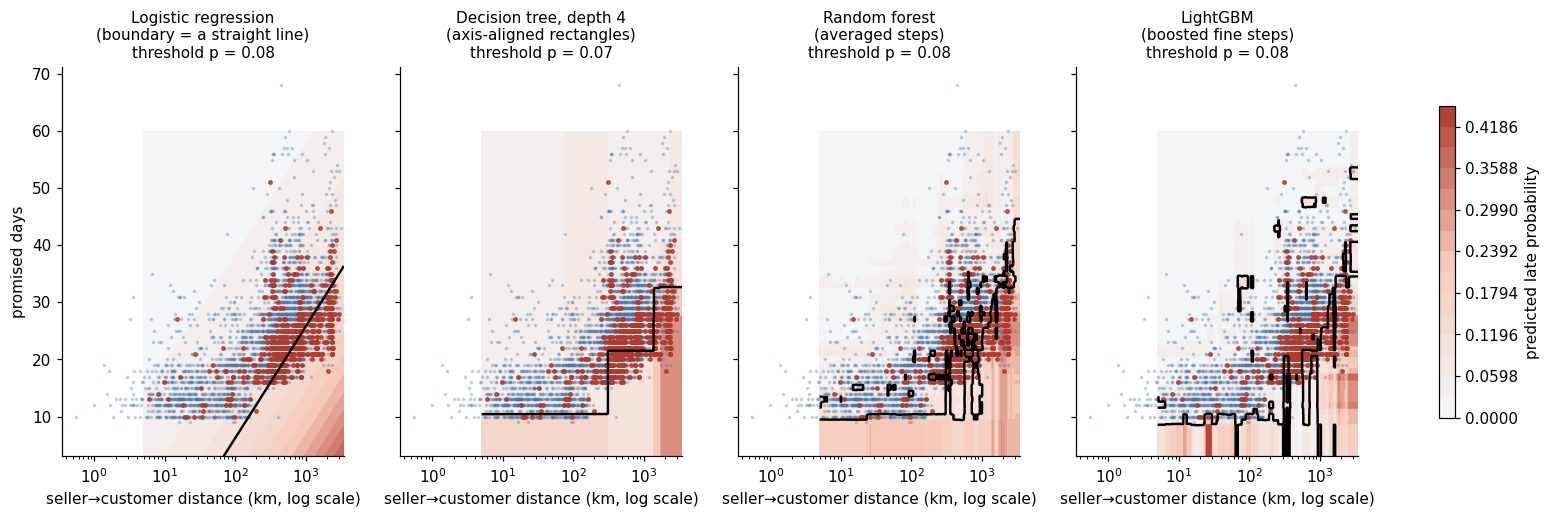

In [4]:
X2_cols = ["distance_km_max", "promised_days"]
def to2(d): return np.column_stack([np.log1p(d.distance_km_max.to_numpy()), d.promised_days.to_numpy()])
X2, y2 = to2(TRAIN), TRAIN.late_day.to_numpy().astype(int)
models2 = {
    "Logistic regression\n(boundary = a straight line)": make_pipeline(StandardScaler(), LogisticRegression()),
    "Decision tree, depth 4\n(axis-aligned rectangles)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=C.SEED),
    "Random forest\n(averaged steps)": RandomForestClassifier(n_estimators=200, min_samples_leaf=50, n_jobs=8, random_state=C.SEED),
    "LightGBM\n(boosted fine steps)": LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, random_state=C.SEED, verbose=-1),
}
gx, gy = np.meshgrid(np.linspace(np.log1p(5), np.log1p(3500), 220), np.linspace(3, 60, 220))
grid = np.column_stack([gx.ravel(), gy.ravel()])
v = VAL.sample(5000, random_state=C.SEED); Xv = to2(v)
cmap = LinearSegmentedColormap.from_list("risk", ["#F4F8FB", "#F6C9B8", "#B03A2E"])
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), sharey=True)
bound = {}
for ax, (name, m) in zip(axes, models2.items()):
    m.fit(X2, y2)
    thr = best_f1_threshold(y2, m.predict_proba(X2)[:, 1]); bound[name.split("\n")[0]] = thr
    pz = m.predict_proba(grid)[:, 1].reshape(gx.shape)
    cs = ax.contourf(np.expm1(gx), gy, pz, levels=np.linspace(0, max(0.3, pz.max()), 16), cmap=cmap)
    ax.contour(np.expm1(gx), gy, pz, levels=[thr], colors="k", linewidths=1.6)
    on, late = v.late_day.to_numpy() == 0, v.late_day.to_numpy() == 1
    ax.scatter(np.expm1(Xv[on, 0]), Xv[on, 1], s=2, c="#4C78A8", alpha=0.25)
    ax.scatter(np.expm1(Xv[late, 0]), Xv[late, 1], s=5, c="#B03A2E", alpha=0.8)
    ax.set_xscale("log"); ax.set_title(f"{name}\nthreshold p = {thr:.2f}", fontsize=10); ax.set_xlabel("seller→customer distance (km, log scale)")
axes[0].set_ylabel("promised days")
fig.colorbar(cs, ax=axes, shrink=0.8, label="predicted late probability")
save("decision_boundaries_2d"); plt.show()

**Reading the picture.** All four models agree on the risky corner: far away (beyond about 300 km) with a short promise. They differ in the *shape* of the frontier.
* The logistic-regression boundary is a single straight line: risk rises smoothly with log-distance and falls with promise length.
* The depth-4 tree cuts the plane into a handful of rectangles, at about 300 km and 1,300 km and at about 11, 22 and 33 promised days.
* The forest and LightGBM bend around local clusters, including small islands. That flexibility can capture real interactions, but it can also memorise noise, and controlling it is the job of tuning in notebook 06.

### The hyperplane in 3-D

With three features, the logistic-regression boundary is a flat **plane**: every point on it has the same predicted probability (the threshold). Orders on the red side of the plane get flagged. The features are standardised log distance, promised days and the as-of destination-state late rate.

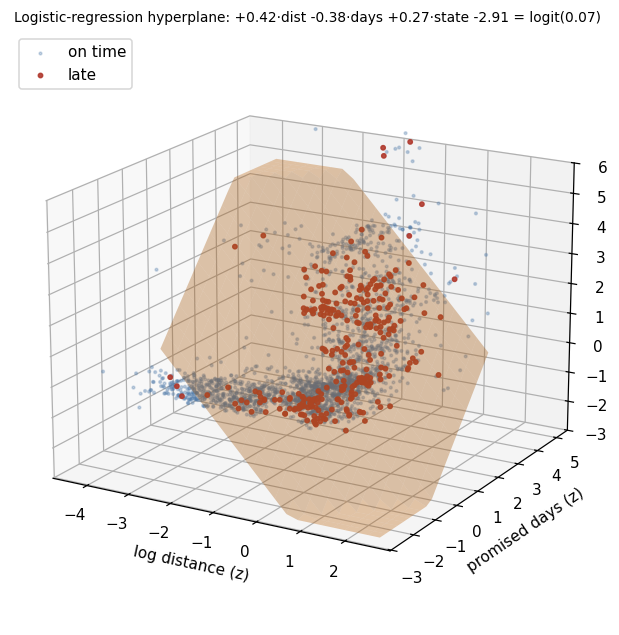

weights (standardised): {'distance_km_max': np.float64(0.425), 'promised_days': np.float64(-0.378), 'dest_state_late_rate': np.float64(0.272)} | intercept -2.908 | threshold 0.071


In [5]:
cols3 = ["distance_km_max", "promised_days", "dest_state_late_rate"]
def to3(d): return np.column_stack([np.log1p(d.distance_km_max), d.promised_days, d.dest_state_late_rate])
sc3 = StandardScaler().fit(to3(TRAIN))
Z, Zv = sc3.transform(to3(TRAIN)), sc3.transform(to3(VAL))
lr3 = LogisticRegression().fit(Z, y2)
thr3 = best_f1_threshold(y2, lr3.predict_proba(Z)[:, 1])
w, b = lr3.coef_[0], lr3.intercept_[0]
logit_t = np.log(thr3 / (1 - thr3))
g1, g2 = np.meshgrid(np.linspace(-2.5, 2.5, 20), np.linspace(-2.5, 2.5, 20))
plane = (logit_t - b - w[0] * g1 - w[1] * g2) / w[2]           # solve w·z + b = logit(t) for z3
fig = plt.figure(figsize=(9, 7)); ax = fig.add_subplot(projection="3d")
ax.plot_surface(g1, g2, np.clip(plane, -3, 6), alpha=0.35, color="#F58518", edgecolor="none")
idx = np.random.default_rng(C.SEED).choice(len(Zv), 2500, replace=False)
yy = VAL.late_day.to_numpy()[idx]
ax.scatter(*Zv[idx][yy == 0].T, s=3, c="#4C78A8", alpha=0.3, label="on time")
ax.scatter(*Zv[idx][yy == 1].T, s=8, c="#B03A2E", alpha=0.9, label="late")
ax.set_xlabel("log distance (z)"); ax.set_ylabel("promised days (z)"); ax.set_zlabel("dest-state late rate (z)")
ax.set_zlim(-3, 6); ax.view_init(elev=18, azim=-60); ax.legend(loc="upper left")
ax.set_title(f"Logistic-regression hyperplane: {w[0]:+.2f}·dist {w[1]:+.2f}·days {w[2]:+.2f}·state {b:+.2f} = logit({thr3:.2f})", fontsize=9)
save("hyperplane_3d"); plt.show()
print("weights (standardised):", dict(zip(cols3, w.round(3))), "| intercept", round(b, 3), "| threshold", round(thr3, 3))

### The hyperplane in the full feature space

The real logistic-regression model uses all the final features (about 120 columns after one-hot encoding), so its hyperplane cannot be drawn. It can still be *measured*. For each order, `w·x + b` is the signed distance to the hyperplane, scaled by ‖w‖. The left panel shows how late and on-time validation orders fall on either side of it. The right panel shows the largest components of the normal vector `w`, the direction that pushes an order across the boundary.

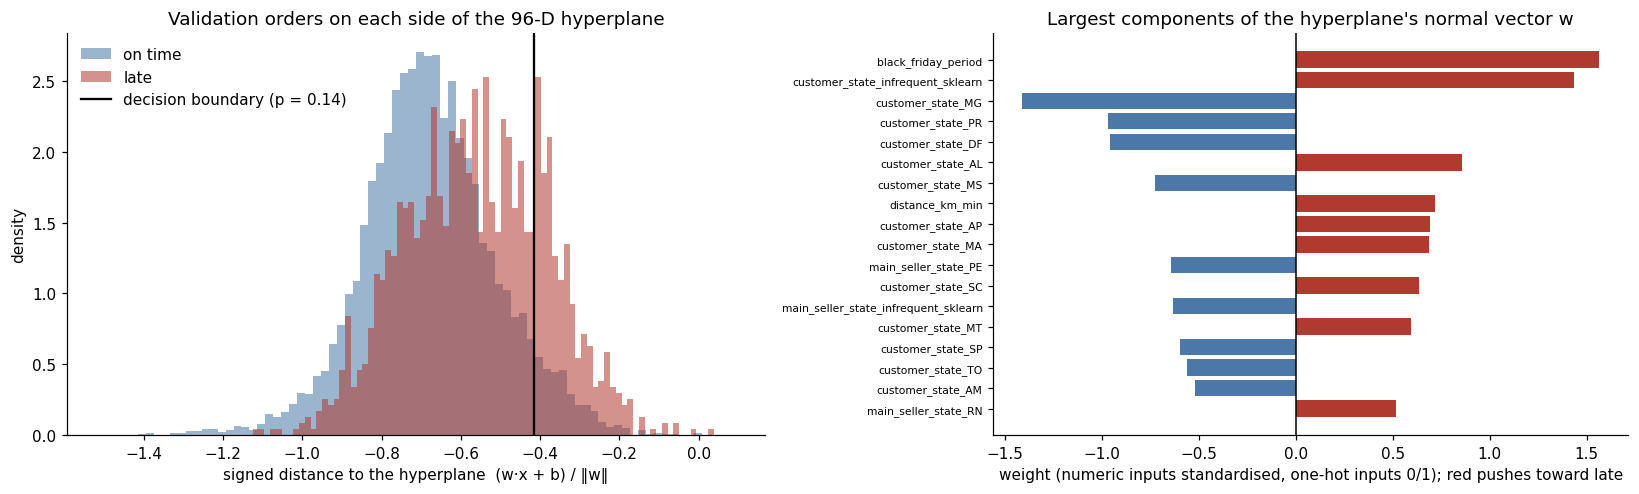

96 design columns | ‖w‖ = 4.27 | late orders beyond boundary: 23.2%, on-time orders beyond boundary: 6.6%


In [6]:
lr_full = make_model("logreg", F).fit(TRAIN[F], TRAIN.late_day)
pre, clf = lr_full.named_steps["pre"], lr_full.named_steps["clf"]
f_val = clf.decision_function(pre.transform(VAL[F]))
w_full = pd.Series(clf.coef_[0], index=pre.get_feature_names_out())
thr_full = best_f1_threshold(TRAIN.late_day, lr_full.predict_proba(TRAIN[F])[:, 1])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
dist = f_val / np.linalg.norm(clf.coef_[0])
for lbl, c, nm in [(0, "#4C78A8", "on time"), (1, "#B03A2E", "late")]:
    axes[0].hist(dist[VAL.late_day.to_numpy() == lbl], bins=80, density=True, alpha=0.55, color=c, label=nm)
axes[0].axvline(np.log(thr_full / (1 - thr_full)) / np.linalg.norm(clf.coef_[0]), color="k", lw=1.5, label=f"decision boundary (p = {thr_full:.2f})")
axes[0].set_xlabel("signed distance to the hyperplane  (w·x + b) / ‖w‖"); axes[0].set_ylabel("density"); axes[0].legend(frameon=False)
axes[0].set_title(f"Validation orders on each side of the {len(w_full)}-D hyperplane")
top = w_full.reindex(w_full.abs().sort_values(ascending=False).index).head(18)[::-1]
axes[1].barh(top.index, top, color=np.where(top > 0, "#B03A2E", "#4C78A8")); axes[1].axvline(0, color="k", lw=1)
axes[1].tick_params(axis="y", labelsize=7); axes[1].set_xlabel("weight (numeric inputs standardised, one-hot inputs 0/1); red pushes toward late")
axes[1].set_title("Largest components of the hyperplane's normal vector w")
plt.tight_layout(); save("hyperplane_full_space"); plt.show()
print(f"{len(w_full)} design columns | ‖w‖ = {np.linalg.norm(clf.coef_[0]):.2f} | late orders beyond boundary: "
      f"{(f_val[VAL.late_day.to_numpy()==1] > np.log(thr_full/(1-thr_full))).mean():.1%}, on-time orders beyond boundary: "
      f"{(f_val[VAL.late_day.to_numpy()==0] > np.log(thr_full/(1-thr_full))).mean():.1%}")

**Reading the picture.** After one-hot encoding the full model has 96 input columns. Late and on-time orders overlap heavily along the hyperplane's normal. At the F1-optimal training threshold (p = 0.14), 23.2% of late validation orders fall on the "late" side, against 6.6% of on-time orders. That is a real but modest separation, consistent with no single feature exceeding ROC-AUC 0.66 in the EDA.

The largest weights belong to the Black Friday window and to destination-state dummies. MG, PR, DF, MS and SP push toward on time. AL, AP, MA, SC, MT and the rare states (pooled into `infrequent_sklearn`) push toward late.

The 3-D model shows the same story directly: distance (+0.42) and destination-state risk (+0.27) push toward late, while a longer promise (−0.38) pulls back. A linear model can only add these effects together; notebook 06 tests whether trees that combine them do better.

In [7]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 71.7s | final RSS 624 MB
